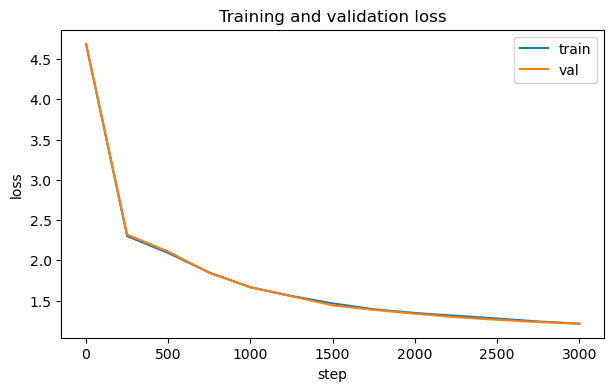

Final train loss: 1.213
Final val loss  : 1.213
Final perplexity: 3.36


In [10]:
# --- Cell 5: Loss curve + perplexity ---
import os, math
import matplotlib.pyplot as plt

os.makedirs("../results", exist_ok=True)

plt.figure(figsize=(7, 4))
plt.plot(s, tr, label="train")
plt.plot(s, va, label="val")
plt.xlabel("step")
plt.ylabel("loss")
plt.title("Training and validation loss")
plt.legend()
plt.savefig("../results/loss_curve.png", dpi=150, bbox_inches="tight")
plt.show()

print("Final train loss:", round(tr[-1], 3))
print("Final val loss  :", round(va[-1], 3))
print("Final perplexity:", round(math.exp(va[-1]), 2))

In [11]:
# --- Cell 2: Tokenize (character level) + train/val split ---
text = "\n<EOS>\n".join(ds["text"][:3000])
chars = sorted(set(text)); vocab_size = len(chars)
stoi = {c: i for i, c in enumerate(chars)}; itos = {i: c for c, i in stoi.items()}
encode = lambda s: [stoi[c] for c in s if c in stoi]
decode = lambda l: "".join(itos[i] for i in l)
data = torch.tensor(encode(text), dtype=torch.long)
n = int(0.9 * len(data)); train_data, val_data = data[:n], data[n:]
print("vocab:", vocab_size, "tokens:", len(data))

cfg = dict(block_size=128, n_embd=128, n_head=4, n_layer=4, dropout=0.1, vocab_size=vocab_size)
batch_size = 64

def get_batch(split):
    d = train_data if split == "train" else val_data
    ix = torch.randint(len(d) - cfg["block_size"] - 1, (batch_size,))
    x = torch.stack([d[i:i+cfg["block_size"]] for i in ix])
    y = torch.stack([d[i+1:i+cfg["block_size"]+1] for i in ix])   # target = input shifted by 1
    return x.to(device), y.to(device)

vocab: 92 tokens: 2629809


In [12]:
# --- Cell 3: Transformer architecture ---
class MaskedSelfAttention(nn.Module):
    def __init__(s, c):
        super().__init__()
        s.n_head = c["n_head"]
        s.qkv = nn.Linear(c["n_embd"], 3*c["n_embd"])
        s.proj = nn.Linear(c["n_embd"], c["n_embd"])
        s.drop = nn.Dropout(c["dropout"])
    def forward(s, x):
        B, T, C = x.shape
        q, k, v = s.qkv(x).split(C, dim=2)
        q, k, v = [t.view(B, T, s.n_head, C // s.n_head).transpose(1, 2) for t in (q, k, v)]
        att = (q @ k.transpose(-2, -1)) / math.sqrt(k.size(-1))
        mask = torch.tril(torch.ones(T, T, device=x.device)).bool()   # causal mask
        att = F.softmax(att.masked_fill(~mask, float("-inf")), dim=-1)
        y = (s.drop(att) @ v).transpose(1, 2).contiguous().view(B, T, C)
        return s.drop(s.proj(y))

class Block(nn.Module):
    def __init__(s, c):
        super().__init__()
        s.ln1 = nn.LayerNorm(c["n_embd"]); s.attn = MaskedSelfAttention(c)
        s.ln2 = nn.LayerNorm(c["n_embd"])
        s.ffn = nn.Sequential(nn.Linear(c["n_embd"], 4*c["n_embd"]), nn.GELU(),
                              nn.Linear(4*c["n_embd"], c["n_embd"]), nn.Dropout(c["dropout"]))
    def forward(s, x):
        x = x + s.attn(s.ln1(x))   # residual
        return x + s.ffn(s.ln2(x)) # residual

class TinyGPT(nn.Module):
    def __init__(s, c):
        super().__init__()
        s.c = c
        s.tok = nn.Embedding(c["vocab_size"], c["n_embd"])
        s.pos = nn.Embedding(c["block_size"], c["n_embd"])
        s.blocks = nn.Sequential(*[Block(c) for _ in range(c["n_layer"])])
        s.ln_f = nn.LayerNorm(c["n_embd"]); s.head = nn.Linear(c["n_embd"], c["vocab_size"])
    def forward(s, idx, targets=None):
        B, T = idx.shape
        x = s.tok(idx) + s.pos(torch.arange(T, device=idx.device))
        logits = s.head(s.ln_f(s.blocks(x)))
        loss = None if targets is None else F.cross_entropy(logits.view(-1, logits.size(-1)), targets.view(-1))
        return logits, loss
    @torch.no_grad()
    def generate(s, idx, max_new=300, temperature=0.8, top_k=20):
        for _ in range(max_new):
            logits, _ = s(idx[:, -s.c["block_size"]:])
            logits = logits[:, -1, :] / temperature
            if top_k:
                v, _ = torch.topk(logits, top_k)
                logits[logits < v[:, [-1]]] = -float("inf")
            idx = torch.cat([idx, torch.multinomial(F.softmax(logits, dim=-1), 1)], dim=1)
        return idx

In [13]:
# --- Cell 4: Training function ---
def run(cfg, steps=3000, eval_every=250, lr=3e-4):
    model = TinyGPT(cfg).to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=lr)
    print("params:", sum(p.numel() for p in model.parameters())/1e6, "M")
    tr_hist, va_hist, steps_hist = [], [], []

    @torch.no_grad()
    def evaluate():
        model.eval(); out = {}
        for sp in ("train", "val"):
            out[sp] = sum(model(*get_batch(sp))[1].item() for _ in range(20)) / 20
        model.train(); return out

    for step in range(steps + 1):
        if step % eval_every == 0:
            e = evaluate()
            tr_hist.append(e["train"]); va_hist.append(e["val"]); steps_hist.append(step)
            print(f"step {step}: train {e['train']:.3f} val {e['val']:.3f} ppl {math.exp(e['val']):.2f}")
        _, loss = model(*get_batch("train"))
        opt.zero_grad(set_to_none=True); loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step()
    return model, steps_hist, tr_hist, va_hist

params: 0.833372 M
step 0: train 4.712 val 4.711 ppl 111.11
step 250: train 2.299 val 2.322 ppl 10.19
step 500: train 2.072 val 2.091 ppl 8.10
step 750: train 1.811 val 1.812 ppl 6.12
step 1000: train 1.635 val 1.624 ppl 5.08
step 1250: train 1.511 val 1.507 ppl 4.51
step 1500: train 1.438 val 1.422 ppl 4.14
step 1750: train 1.377 val 1.352 ppl 3.86
step 2000: train 1.320 val 1.314 ppl 3.72
step 2250: train 1.273 val 1.267 ppl 3.55
step 2500: train 1.242 val 1.224 ppl 3.40
step 2750: train 1.220 val 1.216 ppl 3.37
step 3000: train 1.191 val 1.168 ppl 3.22


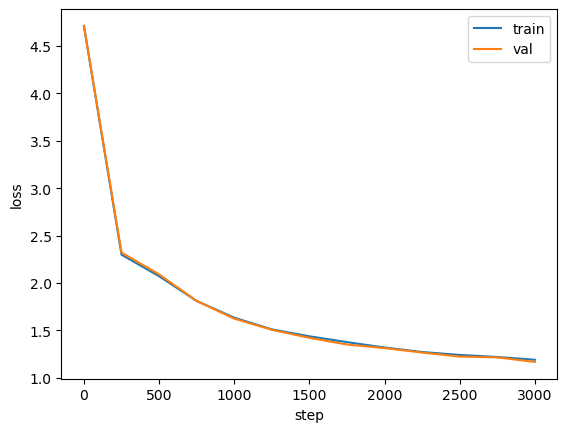

Final perplexity: 3.216090528500754


In [14]:
# --- Cell 5: Train + loss curve + perplexity ---
model, s, tr, va = run(cfg)
plt.plot(s, tr, label="train"); plt.plot(s, va, label="val")
plt.xlabel("step"); plt.ylabel("loss"); plt.legend()
plt.savefig("../results/loss_curve.png"); plt.show()
print("Final perplexity:", math.exp(va[-1]))

In [15]:
# --- Cell 6: Generate stories ---
start = torch.tensor([encode("Once upon a time")], device=device)
print(decode(model.generate(start, 400)[0].tolist()))

Once upon a time and there was a parket own and hand glies and his madme and pretty the blocks. 

The bird and the looy find she was running and the sun asked to small for haise. They said, "I sit way, and it is climbed.

"Mommy you and he came once and in nello, was what it washize. You are t, looking! her moppy and feeling the boy atter, boright he was placess oningtes the boy had a small. They face. They love 


In [16]:
# --- Cell 7: Experiment with layers / heads ---
for nl, nh in [(2, 2), (4, 4), (6, 8)]:
    c = {**cfg, "n_layer": nl, "n_head": nh}
    m, _, _, v = run(c, steps=1500, eval_every=500)
    print(f"layers={nl}, heads={nh}, val_loss={v[-1]:.3f}")
    print(decode(m.generate(start, 200)[0].tolist()), "\n=====")

params: 0.436828 M
step 0: train 4.702 val 4.703 ppl 110.26
step 500: train 2.140 val 2.156 ppl 8.63
step 1000: train 1.779 val 1.770 ppl 5.87
step 1500: train 1.576 val 1.571 ppl 4.81
layers=2, heads=2, val_loss=1.571
Once upon a time the outer ween to a the the was dring the was was a fore didn't t caugirl ared and ran cano potter and the wand ther. 

There bind had sto donem onemes. Some her pueped day. He wan they said, was had 
=====
params: 0.833372 M
step 0: train 4.673 val 4.671 ppl 106.83
step 500: train 2.102 val 2.111 ppl 8.26
step 1000: train 1.643 val 1.636 ppl 5.13
step 1500: train 1.434 val 1.424 ppl 4.15
layers=4, heads=4, val_loss=1.424
Once upon a time, was stoy! It was a down it was frounded on.

And a becacher the pog a big and treand the pola. The bered aske and specit how, sturing to the was so bor very un. It scared, but to fach, corthe store  
=====
params: 1.229916 M
step 0: train 4.706 val 4.709 ppl 110.90
step 500: train 2.038 val 2.046 ppl 7.74
step 1000: tr

In [17]:
# --- Cell 8: Save model ---
torch.save({"state": model.state_dict(), "config": cfg, "chars": chars}, "../results/tiny_gpt.pt")

In [18]:
# --- Cell 9 (Optional): Gradio chat ---
import gradio as gr
def chat(prompt, length, temp):
    ids = torch.tensor([encode(prompt)], device=device)
    return decode(model.generate(ids, int(length), float(temp))[0].tolist())

gr.Interface(chat,
             [gr.Textbox(value="Once upon a time"), gr.Slider(50, 800, value=300), gr.Slider(0.3, 1.5, value=0.8)],
             "text", title="Tiny Story Generator").launch()

* Running on local URL:  http://127.0.0.1:7860
* To create a public link, set `share=True` in `launch()`.
